In [ ]:
pip install openpyxl

In [1]:
import pandas as pd

df = pd.read_excel("data.xlsx")

print(df.head())

  Student  Study Hours  Attendance  Previous Marks  Assignments Result
0      S1            2          45              35            2   Fail
1      S2            3          55              40            3   Fail
2      S3            5          75              60            7   Pass
3      S4            6          80              65            8   Pass
4      S5            1          30              25            1   Fail


In [3]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
df = pd.read_excel("data.xlsx")

# Remove unnecessary ID column
X = df.drop(['Result', 'Student'], axis=1)

# Target variable
y = df['Result']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)


# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))


Accuracy: 1.0
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         2
        Pass       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [5]:
X_test

,Study Hours,Attendance,Previous Marks,Assignments
9,6,85,70,8
11,2,40,30,2
0,2,45,35,2


In [6]:
y_pred

array(['Pass', 'Fail', 'Fail'], dtype=object)

In [7]:
y_test

9     Pass
11    Fail
0     Fail
Name: Result, dtype: object

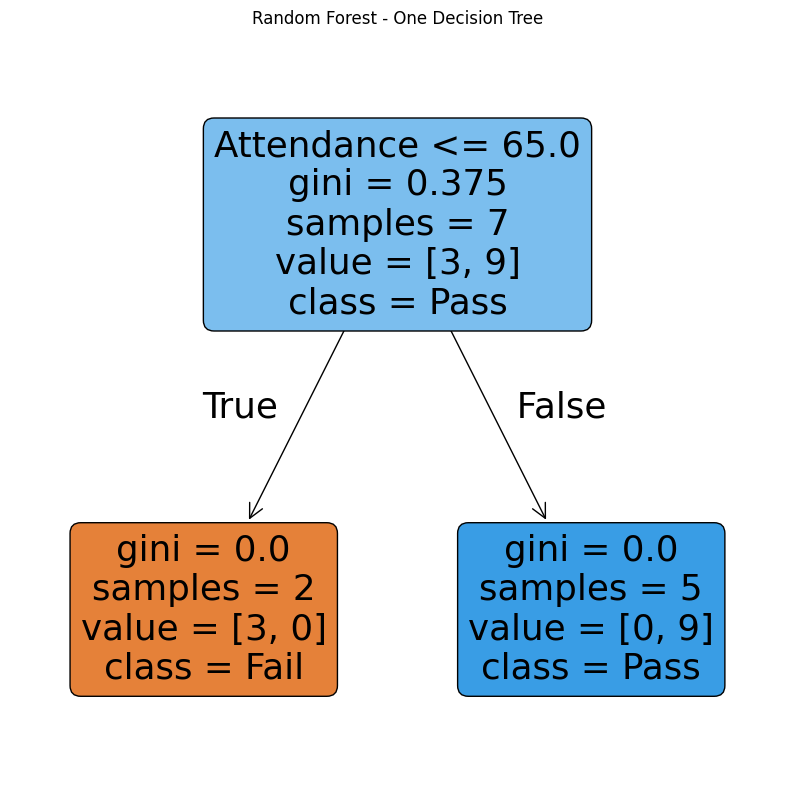

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(10,10))

plot_tree(
    model.estimators_[0],
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Random Forest - One Decision Tree")
plt.show()